# Самостоятельная работа: RGB DCGAN для лиц Olivetti Faces в PyTorch

Цель — самостоятельно реализовать DCGAN в PyTorch с выбором Intel Arc
XPU при доступности и CPU как резервного устройства. Набор Olivetti
отличается от LFW и содержит 400 чёрно-белых лиц. Они приводятся к
трём одинаковым каналам только ради общей формы `(B,3,64,64)`.

Не используйте `nn.RNN`, готовый GAN-слой или метки людей в функции
потерь. Все `TODO(student)` остаются в коде; заголовки показывают
последовательность самостоятельной работы.

## Сюжет самостоятельного эксперимента

Ваша задача — собрать художника и проверяющего из обычных слоёв
PyTorch. Художник получает карточку из 100 чисел и рисует лицо;
проверяющий получает картинку и пытается понять её происхождение.
Сначала всегда подготовьте входы и проверьте форму, затем постройте
сеть, затем выполните одну из двух фаз обучения. Не переходите к
следующей ячейке, пока контрольная точка текущей не пройдена.

### Словарь перед первой реализацией

Параметры — обучаемые числа слоёв. Прямой проход создаёт картинку и
ответ проверяющего. Потеря — одно число, показывающее расхождение с
целью. Градиент — инструкция, как чуть изменить параметры. В PyTorch
`backward()` готовит эти инструкции, а `step()` применяет их.

## Этап 1. Конфигурация устройства и эксперимента

**Требуется:** выбрать `torch.device('xpu')` только при доступности
`torch.xpu.is_available()`, иначе CPU. Зафиксируйте seed, форму шума,
размер пакета, число эпох и каталог артефактов.

**Проверка:** распечатано активное устройство; все последующие тензоры
модели и шум будут перенесены именно на него.

`(B,3,64,64)` означает пачку лиц: `B` — число картинок, 3 — каналы,
два последних числа — высота и ширина. В PyTorch каналы идут раньше
пространственных осей. Любой тензор, участвующий в одном вычислении,
должен находиться на одном `device`; иначе PyTorch не знает, где
выполнять операцию.

In [2]:
from __future__ import annotations

# Эти импорты разделяют роли: NumPy/Matplotlib — подготовка и вывод,
# torch/nn — тензоры, слои и обратное распространение в PyTorch.
from pathlib import Path
from IPython import get_ipython
shell = get_ipython()
if shell is not None:
    shell.run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_olivetti_faces
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Числа задают договор о формах: z=(B,100), изображения=(B,3,64,64).
SEED, IMAGE_SIZE, CHANNELS, NOISE_DIM = 42, 64, 3, 100
BATCH_SIZE, EPOCHS, LEARNING_RATE, BETA_1 = 32, 120, 2e-4, 0.5
REAL_LABEL = 0.9
ARTIFACT_DIR = Path('artifacts/olivetti_face_gan_pytorch')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
# TODO(student): выберите device, зафиксируйте генераторы случайных чисел и выведите конфигурацию.
# Выбирайте torch.device('xpu') только если torch.xpu.is_available().
# Затем фиксируйте torch.manual_seed до создания G/D и при XPU отдельно
# фиксируйте генератор XPU. Все модели, шум и real_images должны быть
# на одном device: смешение CPU и XPU делает прямой проход невозможным.
# raise NotImplementedError('Настройте CPU/XPU-устройство.')
# Выбор устройства: XPU (Intel Arc) при доступности, иначе CPU.
if hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

# Фиксируем генераторы случайных чисел ДО создания моделей.
torch.manual_seed(SEED)
np.random.seed(SEED)
if device.type == "xpu":
    torch.xpu.manual_seed(SEED)

print(f"Устройство: {device}")
print(f"Torch: {torch.__version__}")
print(f"XPU доступен: {hasattr(torch, 'xpu') and torch.xpu.is_available()}")
print(f"Конфигурация: z=({BATCH_SIZE},{NOISE_DIM}), x=({BATCH_SIZE},{CHANNELS},{IMAGE_SIZE},{IMAGE_SIZE}), "
      f"эпох={EPOCHS}, lr={LEARNING_RATE}, beta1={BETA_1}, REAL_LABEL={REAL_LABEL}")

Устройство: cpu
Torch: 2.15.0+cpu
XPU доступен: False
Конфигурация: z=(32,100), x=(32,3,64,64), эпох=120, lr=0.0002, beta1=0.5, REAL_LABEL=0.9


## Этап 2. Матрица лиц и мини-пакеты

**Требуется:** получить Olivetti Faces, преобразовать `(N,64,64)` в
`(N,3,64,64)`, перевести $[0,1]$ в $[-1,1]`, создать `TensorDataset`
и `DataLoader`. В `DataLoader` не должно быть идентификаторов субъектов.

**Контрольная точка:** один пакет реализаций имеет форму
`(BATCH_SIZE, 3, 64, 64)` и конечные значения.

**Маршрут:** получите серое лицо в `[0,1]`, создайте три одинаковых
канала и приведите их к `[-1,1]`. Эти каналы не делают фотографию
цветной: это три одинаковые копии для совместимости с RGB-сетью.
Затем положите в `DataLoader` только картинки. ID субъекта можно
показать в диагностике, но он не является правильным ответом GAN.

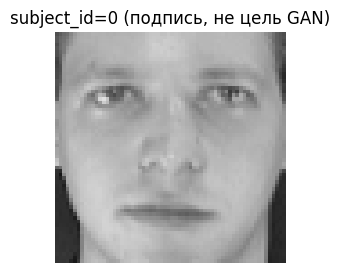

images: (400, 3, 64, 64) | диапазон: (-1.0, 1.0)
первый пакет: (32, 3, 64, 64)


In [3]:
# Вход — Olivetti images=(N,64,64) в [0,1]. Сначала добавьте/повторите
# канал, получив (N,3,64,64): PyTorch Conv2d НЕ принимает NHWC. Затем
# одной формулой нормируйте к [-1,1], чтобы диапазон совпал с tanh G.
# TODO(student): подготовьте images и loader; сохраните subject_ids только для необязательной диагностики.
# TensorDataset должен получить только images: subject_ids не являются
# ни ответами D, ни условием G. DataLoader вернёт кортеж `(images,)`,
# поэтому в цикле обучающий пакет извлекается как `(real_images,)`.
# Проверьте форму, finite и диапазон до первого вызова модели.
# TODO(student): проверьте порядок осей C,H,W, диапазон [-1, 1] и форму первого пакета.
# raise NotImplementedError('Реализуйте подготовку Olivetti Faces.')

# Загрузка Olivetti Faces с фиксированным random_state.
olivetti = fetch_olivetti_faces(random_state=SEED)

# images: (N,64,64) в [0,1]; subject_ids: (N,) — только для диагностики.
images_np = olivetti.images.astype("float32")
subject_ids = olivetti.target

# (N,64,64) -> (N,1,64,64) -> (N,3,64,64): три одинаковых серых канала.
images_np = np.expand_dims(images_np, axis=1)        # (N,1,64,64)
images_np = np.repeat(images_np, CHANNELS, axis=1)   # (N,3,64,64)

# [0,1] -> [-1,1]: та же шкала, что у tanh генератора.
images_np = images_np * 2.0 - 1.0

# Тензор и DataLoader только из изображений.
images_tensor = torch.from_numpy(images_np).float()
dataset = TensorDataset(images_tensor)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

# Контрольные проверки.
assert images_tensor.shape == (len(images_np), CHANNELS, IMAGE_SIZE, IMAGE_SIZE), images_tensor.shape
assert torch.isfinite(images_tensor).all()
assert images_tensor.min() >= -1.0 and images_tensor.max() <= 1.0
real_batch_check, = next(iter(loader))
assert real_batch_check.shape == (BATCH_SIZE, CHANNELS, IMAGE_SIZE, IMAGE_SIZE), real_batch_check.shape

# Диагностика: одно лицо до обучения.
plt.figure(figsize=(3, 3))
img0 = ((images_tensor[0] + 1.0) / 2.0).permute(1, 2, 0).numpy()
plt.imshow(img0)
plt.title(f"subject_id={subject_ids[0]} (подпись, не цель GAN)")
plt.axis("off")
plt.show()

print("images:", tuple(images_tensor.shape), "| диапазон:",
      (float(images_tensor.min()), float(images_tensor.max())))
print("первый пакет:", tuple(real_batch_check.shape))

## Этап 3. Классы генератора и дискриминатора

**Требуется:** определить `DCGenerator` на `ConvTranspose2d` и
`DCDiscriminator` на `Conv2d`. Генератор получает `(B,100)` и выдаёт
`(B,3,64,64)` через `tanh`; дискриминатор возвращает один логит
`(B,1)` без sigmoid.

**Контрольная точка:** параметры обеих моделей находятся на `device`,
формы диагностического прохода точны.

Генератор делает маленькую внутреннюю карту, а затем увеличивает её
ступенями до $64\times64$. Дискриминатор делает обратное: постепенно
уменьшает карту и выдаёт один логит. Логит — не вероятность и не номер
человека; это свободная оценка «похоже на настоящее». Поэтому функция
потерь будет сама обрабатывать его как вход sigmoid.

In [4]:
# DCGenerator: z=(B,100) добавляет две оси и становится (B,100,1,1).
# ConvTranspose2d должен последовательно увеличить карту 1→4→8→16→32→64
# и вернуть (B,3,64,64) с Tanh. DCDiscriminator делает обратное сжатие
# Conv2d и возвращает логит (B,1) без sigmoid.
# TODO(student): реализуйте классы DCGenerator и DCDiscriminator на nn.Module.
# Каждый созданный модуль перенесите на device. Диагностический z также
# создайте на device и проверьте формы G(z), D(G(z)), число параметров
# и конечность. Это ещё не обучение: backward/step здесь не вызываются.
# TODO(student): создайте модели на device и выполните диагностический проход.
# raise NotImplementedError('Реализуйте архитектуру DCGAN.')

class DCGenerator(nn.Module):
    def __init__(self, noise_dim: int = NOISE_DIM, channels: int = CHANNELS):
        super().__init__()
        # z=(B,100,1,1) -> 4x4x512 -> 8x8x256 -> 16x16x128 -> 32x32x64 -> 64x64xC
        self.net = nn.Sequential(
            nn.ConvTranspose2d(noise_dim, 512, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.net(z.view(z.size(0), z.size(1), 1, 1))


class DCDiscriminator(nn.Module):
    def __init__(self, channels: int = CHANNELS):
        super().__init__()
        # (B,3,64,64) -> (B,64,32,32) -> (B,128,16,16) -> (B,256,8,8) -> (B,512,4,4) -> логит (B,1)
        self.features = nn.Sequential(
            nn.Conv2d(channels, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
        )
        self.head = nn.Linear(512 * 4 * 4, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.features(x)
        h = h.view(h.size(0), -1)
        return self.head(h)  # логит (B,1), без sigmoid


# Создание моделей и перенос на device.
G = DCGenerator().to(device)
D = DCDiscriminator().to(device)

# Диагностический проход (без backward/step).
z_check = torch.randn(BATCH_SIZE, NOISE_DIM, device=device)
with torch.no_grad():
    fake_check = G(z_check)
    logits_check = D(fake_check)

assert fake_check.shape == (BATCH_SIZE, CHANNELS, IMAGE_SIZE, IMAGE_SIZE), fake_check.shape
assert logits_check.shape == (BATCH_SIZE, 1), logits_check.shape
assert torch.isfinite(fake_check).all() and torch.isfinite(logits_check).all()
assert fake_check.min() >= -1.0 and fake_check.max() <= 1.0
assert next(G.parameters()).device.type == device.type
assert next(D.parameters()).device.type == device.type

print("G(z):", tuple(fake_check.shape), "| диапазон:",
      (float(fake_check.min()), float(fake_check.max())))
print("D(G(z)):", tuple(logits_check.shape))
print("параметров G:", sum(p.numel() for p in G.parameters()))
print("параметров D:", sum(p.numel() for p in D.parameters()))

G(z): (32, 3, 64, 64) | диапазон: (-0.9994667768478394, 0.9999553561210632)
D(G(z)): (32, 1)
параметров G: 3576704
параметров D: 2763777


## Этап 4. BCE по логитам и состязательный шаг

**Требуется:** использовать `BCEWithLogitsLoss`, два Adam-оптимизатора
и два обратных прохода. При обновлении дискриминатора создавайте
синтетические лица без градиента генератора. При обновлении генератора
временно отключайте градиенты параметров дискриминатора, но не путь
производной через его операции.

**Проверка:** реальные цели 0.9, синтетические 0, цель генератора 1;
после каждого подшага конечна только соответствующая потеря и
обновляется правильный набор параметров.

**Первая половина:** `no_grad` просит художника нарисовать картинку,
но не запоминает путь её создания. Проверяющий учится отличать её от
настоящей фотографии. **Вторая половина:** `requires_grad_(False)`
замораживает веса проверяющего, но оставляет открытую дорогу замечанию
через него к художнику. Не путайте эти действия: первое отрезает путь
градиента, второе отрезает только обновление весов D.

`zero_grad → backward → step` можно читать буквально: стереть старые
замечания, посчитать новые, применить поправку. В первой половине это
делает `opt_d`, во второй — `opt_g`.

D вернёт логит $\ell$, а не вероятность. Мысленно вероятность получается
после sigmoid: $p=1/(1+e^{-\ell})$. Для цели $y$ бинарная ошибка равна

$$
\operatorname{BCE}(y,p)=-y\log p-(1-y)\log(1-p).
$$

`BCEWithLogitsLoss` принимает сам логит и устойчиво объединяет sigmoid
с этой формулой. Отдельный sigmoid перед функцией потерь поэтому не
добавляется.

### Точная цель каждой команды

**Сначала проследите один пакет глазами данных.**

![Два независимых обновления GAN: обучение дискриминатора, затем обучение генератора](assets/diagrams/gan_two_phase_training.svg)

Синие блоки схемы — временные данные одного шага, зелёные — параметры
сетей, красные — потери-скаляры. Реальный пакет и шум не обучаются:
они только приходят на вход. `opt_d` и `opt_g` могут менять лишь
параметры, которые были переданы им при создании.

Пусть $\theta_G$ обозначает веса генератора, а $\theta_D$ — веса
дискриминатора. Одна потеря — скаляр. Градиент показывает, как слегка
сдвинуть каждый вес, чтобы эта потеря уменьшилась:

$$
\theta\leftarrow\theta-\eta\nabla_\theta\mathcal L.
$$

В фазе D вычислите среднюю потерю настоящих лиц с целью 0.9 и
сгенерированных лиц с целью 0; затем применяйте её только к
$\theta_D$. В фазе G вычислите

$$
\mathcal L_G=\operatorname{BCE}(1,D_{\theta_D}(G_{\theta_G}(\mathbf z_G)))
$$

и применяйте результат только к $\theta_G$. Шум $\mathbf z_G$ не
является параметром: он лишь новый вход художника.

### Как Autograd и оптимизатор реализуют это правило

![Жизненный цикл динамического графа PyTorch и обновления Adam](assets/diagrams/pytorch_autograd.svg)

Обычный прямой проход автоматически создаёт динамический граф:
промежуточный тензор помнит в `grad_fn`, какой операцией был получен.
`loss.backward()` начинает со скаляра потери, применяет цепное правило
к этим операциям и помещает результат рядом с каждым параметром в
`parameter.grad`; градиент матрицы весов — матрица той же формы.
`zero_grad(set_to_none=True)` нужен потому, что PyTorch складывает
градиенты нескольких обратных проходов. `optimizer.step()` затем берёт
только параметры, с которыми был создан этот оптимизатор, и применяет
к их `.grad` правило Adam. После обычного `backward()` временный граф
шага освобождается.

В фазе G путь

$$
\frac{\partial\mathcal L_G}{\partial\theta_G}
=\frac{\partial\mathcal L_G}{\partial D}
\frac{\partial D}{\partial G}
\frac{\partial G}{\partial\theta_G}
$$

должен остаться открытым. Поэтому заморозка $\theta_D$ не заменяется
на `no_grad`: D не накапливает свои производные, но всё ещё передаёт
множитель $\partial D/\partial G$ к генератору.

### Один мини-пакет: чек-лист объектов будущей реализации

| Объект | Рекомендуемое имя | Форма | Что требуется от него |
| --- | --- | --- | --- |
| Реальный пакет | `real_images` | `(B,3,64,64)` | Находится на `device`; цель D равна 0.9. |
| Шум фазы D | `discriminator_noise` | `(B,100)` | Используется внутри `torch.no_grad()`. |
| Поддельный пакет D | `fake_images` | `(B,3,64,64)` | Передаётся D с целью 0. |
| Потеря D | `d_loss` | скаляр | После `backward()` заполняет `.grad` только D. |
| Шум фазы G | `generator_noise` | `(B,100)` | Новый тензор на `device`. |
| Генерация | `generated` | `(B,3,64,64)` | Не должна быть в `no_grad()` или `detach()`. |
| Потеря G | `g_loss` | скаляр | После `backward()` заполняет `.grad` только G. |

**Контроль понимания перед TODO.** `fake_images` первой фазы — уже
готовый тензор данных `(B,3,64,64)` без записанного пути к G, потому
что он построен в `torch.no_grad()`. `generated` второй фазы имеет ту
же форму, но создаётся вне `no_grad()`: его связь с G обязательна для
обратного распространения. `requires_grad_(False)` у параметров D не
равен `no_grad()`: первый режим не заполняет `.grad` D, но не закрывает
путь вычислений от логита D к изображению генератора.

В полной векторной записи обратный путь фазы G выглядит так:

$$
\nabla_{\theta_G}\mathcal L_G
=J_{G,\theta_G}^{\mathsf T}
J_{D,\mathbf x}^{\mathsf T}
\nabla_{\ell}\mathcal L_G.
$$

Якобианы $J$ описывают локальные зависимости «веса G → пиксели» и
«пиксели → логит D». `backward()` не хранит всю такую огромную таблицу;
он сразу распространяет её нужное действие на градиент скалярной
потери в обратном направлении.

После создания `opt_d` и `opt_g` читайте цикл в строгом порядке:
`opt_d.zero_grad` → прямой проход D → `d_loss.backward` →
`opt_d.step`, затем заморозка D → `opt_g.zero_grad` → прямой проход G
через D → `g_loss.backward` → `opt_g.step` → восстановление D. В этом
списке только `step` меняет параметры; `backward` вычисляет и хранит
производные, а `zero_grad` очищает предыдущие.

In [5]:
# criterion=nn.BCEWithLogitsLoss принимает логиты (B,1), не вероятности;
# отдельный sigmoid добавлять нельзя. Создайте opt_g только из θ_G и
# opt_d только из θ_D: у Adam есть собственные моменты для каждого веса.
# TODO(student): создайте criterion, opt_g, opt_d и функцию train_step либо эквивалентный код цикла.
# Фаза D: opt_d.zero_grad; G.eval + torch.no_grad для z_D→fake_images;
# цели D(real)=0.9, D(fake)=0; вычислите два BCE, усредните, вызовите
# d_loss.backward и opt_d.step. В этой фазе граф G отсутствует.
# Фаза G: временно parameter.requires_grad_(False) для θ_D и D.eval;
# opt_g.zero_grad; новый z_G→generated→D(generated); цель равна 1.
# Здесь НЕЛЬЗЯ использовать no_grad/detach для generated: путь
# L_G→D-операции→generated→θ_G обязан остаться дифференцируемым.
# TODO(student): реализуйте раздельное замораживание параметров и проверку конечности потерь.
# После g_loss.backward вызовите только opt_g.step и восстановите
# D.train()/requires_grad_(True) до следующей фазы D. Контроль: обе
# потери — конечные скаляры; параметры обновляет только свой optimizer.
# raise NotImplementedError('Реализуйте попеременное обучение GAN.')

# BCEWithLogitsLoss принимает логиты (B,1); отдельный sigmoid не добавляется.
criterion = nn.BCEWithLogitsLoss()

# Два независимых Adam: моменты для θ_G и θ_D не смешиваются.
opt_g = torch.optim.Adam(G.parameters(), lr=LEARNING_RATE, betas=(BETA_1, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=LEARNING_RATE, betas=(BETA_1, 0.999))


def train_step(real_images: torch.Tensor):
    """Одна итерация: сначала D, затем G. Возвращает (d_loss, g_loss) как float."""
    real_images = real_images.to(device)
    batch_size = real_images.size(0)

    # ---------- Фаза D: обновляем только θ_D ----------
    D.train()
    G.eval()
    opt_d.zero_grad(set_to_none=True)

    # Синтетика для D: no_grad отрезает путь к G в этой фазе.
    with torch.no_grad():
        discriminator_noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_images = G(discriminator_noise)

    real_logits = D(real_images)
    fake_logits = D(fake_images)

    real_targets = torch.full_like(real_logits, REAL_LABEL)
    fake_targets = torch.zeros_like(fake_logits)

    d_loss = 0.5 * (criterion(real_logits, real_targets) + criterion(fake_logits, fake_targets))
    d_loss.backward()
    opt_d.step()

    # ---------- Фаза G: обновляем только θ_G ----------
    # Замораживаем параметры D, но НЕ операции D: путь L_G→D→G должен остаться открытым.
    for p in D.parameters():
        p.requires_grad_(False)
    D.eval()
    G.train()
    opt_g.zero_grad(set_to_none=True)

    generator_noise = torch.randn(batch_size, NOISE_DIM, device=device)
    generated = G(generator_noise)              # вне no_grad: связь с G сохранена
    generated_logits = D(generated)             # D пропускает градиент к пикселям
    generator_targets = torch.ones_like(generated_logits)
    g_loss = criterion(generated_logits, generator_targets)
    g_loss.backward()
    opt_g.step()

    # Восстанавливаем D для следующей фазы D.
    for p in D.parameters():
        p.requires_grad_(True)
    D.train()

    return float(d_loss.detach()), float(g_loss.detach())


# Контроль: один шаг, потери конечны, обновляются правильные наборы.
real_batch, = next(iter(loader))
d_loss, g_loss = train_step(real_batch)
assert np.isfinite(d_loss) and np.isfinite(g_loss)
print(f"один шаг: L_D={d_loss:.4f}, L_G={g_loss:.4f}")


def snapshot(module):
    return [p.detach().clone() for p in module.parameters()]


g_before, d_before = snapshot(G), snapshot(D)
train_step(next(iter(loader))[0])
g_after, d_after = snapshot(G), snapshot(D)

assert any(not torch.equal(b, a) for b, a in zip(g_before, g_after))
assert any(not torch.equal(b, a) for b, a in zip(d_before, d_after))
print("оба набора параметров обновились; фазы D/G работают независимо")

один шаг: L_D=0.6935, L_G=0.6352
оба набора параметров обновились; фазы D/G работают независимо


## Этап 5. Генерации, кривые и анализ

**Требуется:** сохранить фиксированный набор из 64 шумовых векторов,
периодически строить сетки лиц и собрать средние потери по эпохам.
Проверьте, что XPU действительно использовался, если он доступен.

**Итог:** в отчёте укажите устройство, профиль, формы тензоров,
динамику двух потерь, разнообразие образцов и возможные признаки
коллапса мод. Не приписывайте сгенерированным изображениям личность
реальных субъектов.

Фиксированный шум — одинаковый экзамен для художника до и после
обучения. Для экрана его результат переводится из `[-1,1]` в `[0,1]`
и из `(C,H,W)` в `(H,W,C)`. Кривые потерь не заменяют просмотр сетки:
одинаковые или чёрные кадры и бесконечные числа важнее красивой линии.

эпоха   1/120 | L_D=0.5550 | L_G=0.1343
эпоха  10/120 | L_D=0.6199 | L_G=1.7053
эпоха  20/120 | L_D=0.5110 | L_G=1.8702
эпоха  30/120 | L_D=0.6355 | L_G=2.0970
эпоха  40/120 | L_D=0.4390 | L_G=1.6651
эпоха  50/120 | L_D=0.4361 | L_G=1.9420
эпоха  60/120 | L_D=0.4415 | L_G=1.7252
эпоха  70/120 | L_D=0.4780 | L_G=1.6459
эпоха  80/120 | L_D=0.5107 | L_G=1.6506
эпоха  90/120 | L_D=0.4331 | L_G=1.8893
эпоха 100/120 | L_D=0.5046 | L_G=1.7001
эпоха 110/120 | L_D=0.4562 | L_G=1.4109
эпоха 120/120 | L_D=0.4790 | L_G=1.8595


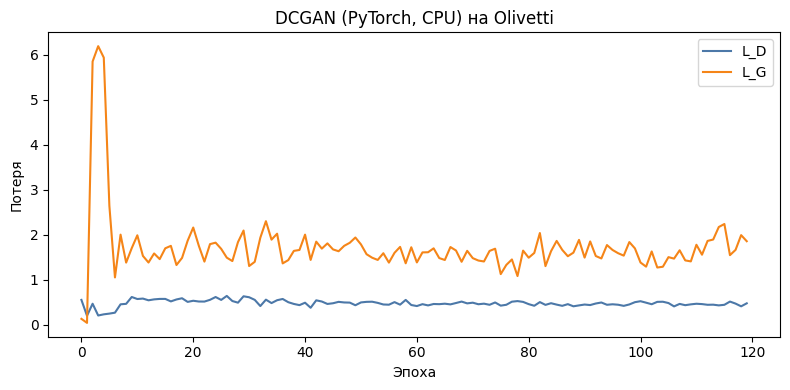

использованное устройство моделей: cpu
Сохранено в: artifacts\olivetti_face_gan_pytorch


In [6]:
# fixed_noise=(64,100) создаётся ровно один раз. Визуализация использует
# G.eval() и torch.no_grad(), затем переводит (B,3,H,W),[-1,1] в
# (B,H,W,3),[0,1] для Matplotlib с vmin=0 и vmax=1. Это безопасно,
# потому что сетка не должна получать градиенты.
# TODO(student): реализуйте полный цикл обучения, визуализацию и итоговую самопроверку.
# raise NotImplementedError('Завершите эксперимент DCGAN.')

# Фиксированный набор из 64 векторов — один и тот же экзамен для G.
fixed_noise = torch.randn(64, NOISE_DIM, device=device)


def make_grid(model, noise, path):
    model.eval()
    with torch.no_grad():
        samples = model(noise).detach().cpu()
    samples = (samples + 1.0) / 2.0                       # [-1,1] -> [0,1]
    samples = samples.clamp(0.0, 1.0)
    samples = samples.permute(0, 2, 3, 1).numpy()         # (B,C,H,W) -> (B,H,W,C)
    fig, axes = plt.subplots(8, 8, figsize=(10, 10))
    for i, ax in enumerate(axes.flat):
        ax.imshow(samples[i])
        ax.axis("off")
    fig.suptitle(path.stem)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)
    model.train()


def run_experiment(epochs: int):
    # Полный перезапуск: свежие веса и оптимизаторы.
    torch.manual_seed(SEED)
    if device.type == "xpu":
        torch.xpu.manual_seed(SEED)

    global G, D, opt_g, opt_d
    G = DCGenerator().to(device)
    D = DCDiscriminator().to(device)
    opt_g = torch.optim.Adam(G.parameters(), lr=LEARNING_RATE, betas=(BETA_1, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=LEARNING_RATE, betas=(BETA_1, 0.999))

    history = {"d_loss": [], "g_loss": []}
    for epoch in range(1, epochs + 1):
        d_running, g_running, n_batches = 0.0, 0.0, 0
        for real_batch, in loader:
            d_loss, g_loss = train_step(real_batch)
            d_running += d_loss
            g_running += g_loss
            n_batches += 1
        history["d_loss"].append(d_running / n_batches)
        history["g_loss"].append(g_running / n_batches)

        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            make_grid(G, fixed_noise, ARTIFACT_DIR / f"grid_epoch_{epoch:03d}.png")
            print(f"эпоха {epoch:3d}/{epochs} | L_D={history['d_loss'][-1]:.4f} "
                  f"| L_G={history['g_loss'][-1]:.4f}")

    assert all(np.isfinite(v) for v in history["d_loss"] + history["g_loss"])
    return history


history = run_experiment(EPOCHS)

# График двух потерь.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["d_loss"], label="L_D", color="#4c78a8")
ax.plot(history["g_loss"], label="L_G", color="#f58518")
ax.set_xlabel("Эпоха")
ax.set_ylabel("Потеря")
ax.set_title(f"DCGAN (PyTorch, {device.type.upper()}) на Olivetti")
ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "loss_curves.png", dpi=110)
plt.show()

# Проверка фактически использованного устройства.
used_device = next(G.parameters()).device.type
print("использованное устройство моделей:", used_device)
if hasattr(torch, "xpu") and torch.xpu.is_available():
    assert used_device == "xpu", "XPU доступен, но модель не на XPU"
print("Сохранено в:", ARTIFACT_DIR)